In [1]:
import numpy as np
import aerosandbox as asb
import neuralfoil as nf
import matplotlib.pyplot as plt
import pandas as pd

print("All libraries imported successfully!")
print("NumPy version:", np.__version__)

All libraries imported successfully!
NumPy version: 2.5.4


In [2]:
# Define the airfoil
airfoil = asb.Airfoil("naca4412")

# Angles of attack in degrees
alpha = np.linspace(-10, 20, 121)

# Reynolds number
Re = 5e5

# Calculate aerodynamic coefficients using NeuralFoil
aero = nf.get_aero_from_airfoil(
    airfoil=airfoil,
    alpha=alpha,
    Re=Re,
    model_size="large"
)

# Extract lift and drag coefficients
cl = np.asarray(aero["CL"])
cd = np.asarray(aero["CD"])

print("Number of data points:", len(alpha))
print("Lift data shape:", cl.shape)
print("Drag data shape:", cd.shape)

print("First five lift coefficients:", cl[:5])
print("First five drag coefficients:", cd[:5])

Number of data points: 121
Lift data shape: (121,)
Drag data shape: (121,)
First five lift coefficients: [-0.67538906 -0.64503433 -0.61384379 -0.5821224  -0.550102  ]
First five drag coefficients: [0.02205867 0.02109052 0.0201722  0.01930552 0.01849116]


In [3]:
# Calculate lift-to-drag ratio
cl_cd = cl / cd

# Find the angle with the maximum ratio
max_index = np.argmax(cl_cd)

best_alpha = alpha[max_index]
best_cl = cl[max_index]
best_cd = cd[max_index]
best_ratio = cl_cd[max_index]

print(f"Best angle of attack: {best_alpha:.2f} degrees")
print(f"Lift coefficient: {best_cl:.4f}")
print(f"Drag coefficient: {best_cd:.5f}")
print(f"Maximum Cl/Cd ratio: {best_ratio:.2f}")

Best angle of attack: 5.75 degrees
Lift coefficient: 1.0889
Drag coefficient: 0.01009
Maximum Cl/Cd ratio: 107.95


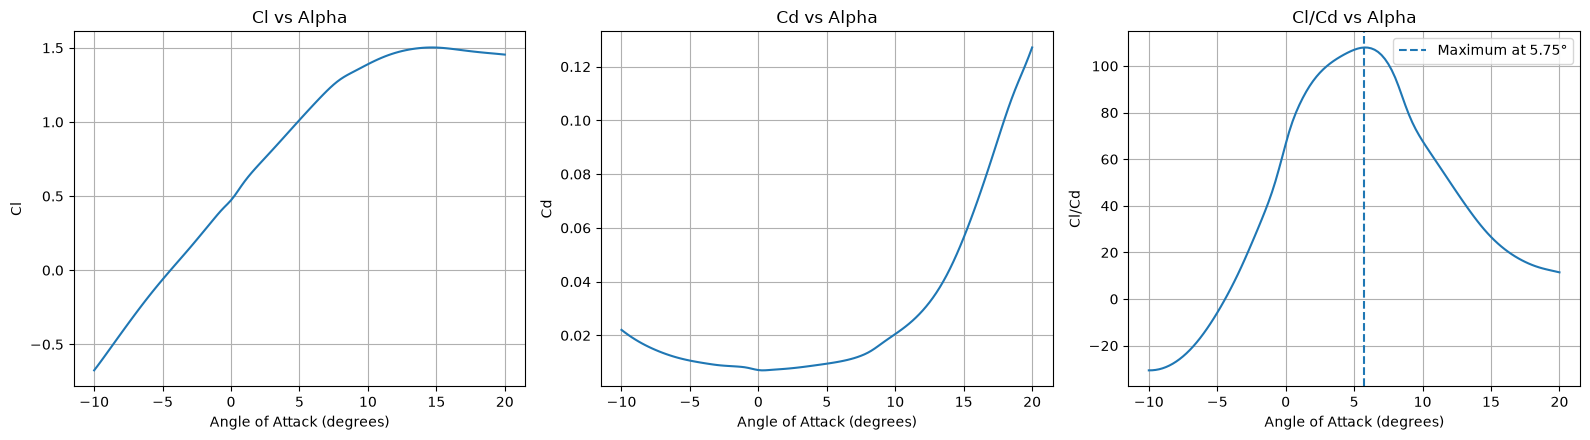

In [6]:
from pathlib import Path

results_dir = Path("../results")
figures_dir = Path("../figures")

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(alpha, cl)
axes[0].set(xlabel="Angle of Attack (degrees)",
            ylabel="Cl", title="Cl vs Alpha")
axes[0].grid(True)

axes[1].plot(alpha, cd)
axes[1].set(xlabel="Angle of Attack (degrees)",
            ylabel="Cd", title="Cd vs Alpha")
axes[1].grid(True)

axes[2].plot(alpha, cl_cd)
axes[2].axvline(best_alpha, linestyle="--",
                label=f"Maximum at {best_alpha:.2f}°")
axes[2].set(xlabel="Angle of Attack (degrees)",
            ylabel="Cl/Cd", title="Cl/Cd vs Alpha")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
fig.savefig(figures_dir / "naca4412_polars.png", dpi=300,
            bbox_inches="tight")
plt.show()

In [5]:
# Combine all data into one table
df = pd.DataFrame({
    "alpha_deg": alpha,
    "Cl": cl,
    "Cd": cd,
    "Cl_Cd": cl_cd
})

# Save the table
df.to_csv("../results/naca4412_polar.csv", index=False)

print(df.head())
print("Saved aerodynamic data to results/naca4412_polar.csv")

   alpha_deg        Cl        Cd      Cl_Cd
0     -10.00 -0.675389  0.022059 -30.617845
1      -9.75 -0.645034  0.021091 -30.584092
2      -9.50 -0.613844  0.020172 -30.430183
3      -9.25 -0.582122  0.019306 -30.153156
4      -9.00 -0.550102  0.018491 -29.749466
Saved aerodynamic data to results/naca4412_polar.csv


In [7]:
def polar(a_rad):
    """Return Cl and Cd for an angle in radians."""
    angle_deg = np.degrees(a_rad)

    cl_value = np.interp(angle_deg, alpha, cl)
    cd_value = np.interp(angle_deg, alpha, cd)

    return cl_value, cd_value


# Test the function at 5 degrees
test_angle_rad = np.radians(5.0)

test_cl, test_cd = polar(test_angle_rad)

print(f"Cl at 5 degrees: {test_cl:.4f}")
print(f"Cd at 5 degrees: {test_cd:.5f}")

Cl at 5 degrees: 1.0133
Cd at 5 degrees: 0.00947
